In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from collections import Counter

In [3]:
df = pd.read_csv("fakenews.csv")

In [4]:
# Load spaCy English model
nlp = spacy.load("en_core_web_sm")

In [5]:
# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

In [6]:
# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Function to extract named entities
def extract_entities(text):
    doc = nlp(text)

    entities = []

    for ent in doc.ents:
        if ent.label_ in ["PERSON", "ORG", "GPE", "LOC"]:
            entities.append({
                "entity": ent.text,
                "type": ent.label_
            })

    return entities

In [7]:

# Extract entities from each article
df["entities"] = df["text"].apply(extract_entities)

# Convert extracted entities into a separate table
entity_records = []

for _, row in df.iterrows():
    for entity in row["entities"]:
        entity_records.append({
            "news_id": row["news_id"],
            "label": row["label"],
            "entity": entity["entity"],
            "entity_type": entity["type"]
        })

entities_df = pd.DataFrame(
    entity_records,
    columns=["news_id", "label", "entity", "entity_type"]
)

# Display extracted entities
print("\nExtracted Named Entities:")
print(entities_df.head(20))


Extracted Named Entities:
    news_id label               entity entity_type
0         2  Real           Chittagong         GPE
1         3  Fake         Breakthrough      PERSON
2         3  Fake           Bangladesh         GPE
3         6  Fake           Chittagong         GPE
4         9  Fake           Chittagong         GPE
5        13  Real           Chittagong         GPE
6        14  Real  the moon Government         ORG
7        19  Real           Bangladesh         GPE
8        21  Fake           Bangladesh         GPE
9        22  Real           Chittagong         GPE
10       22  Real          Uncertainty         ORG
11       23  Fake           Chittagong         GPE
12       23  Fake          Uncertainty         ORG
13       24  Real         Breakthrough      PERSON
14       24  Real           Bangladesh         GPE
15       26  Real         Breakthrough      PERSON
16       26  Real           Bangladesh         GPE
17       27  Fake           Chittagong         GPE
18  


Entity Distribution in Real and Fake News:
entity_category  Locations  Organizations  People
label                                            
Fake                   404            138     128
Real                   428            118      98

Total Entity Occurrences by Label:
label
Fake    670
Real    644
Name: count, dtype: int64

Top 10 Entities in Real News:
entity
Bangladesh              239
Chittagong              120
Breakthrough             98
Dhaka                    55
Uncertainty              18
the moon Uncertainty     14
Local                    14
Dhaka Local              13
the moon Doctors         13
Dhaka Doctors            12
Name: count, dtype: int64

Top 10 Entities in Fake News:
entity
Bangladesh              239
Breakthrough            128
Chittagong              111
Dhaka                    39
Uncertainty              19
the moon Government      18
Dhaka Uncertainty        16
the moon Uncertainty     15
the moon Doctors         14
Dhaka Incidents          13
Na

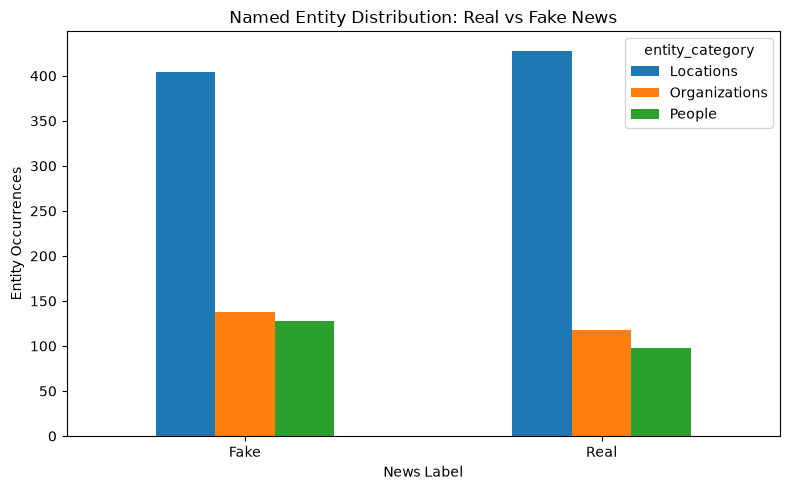


Extracted entities saved successfully.


In [8]:
# Map entity labels to readable names
entity_type_names = {
    "PERSON": "People",
    "ORG": "Organizations",
    "GPE": "Locations",
    "LOC": "Locations"
}

if not entities_df.empty:
    entities_df["entity_category"] = (
        entities_df["entity_type"].map(entity_type_names)
    )

    # Count entities by news label and category
    print("\nEntity Distribution in Real and Fake News:")

    distribution = pd.crosstab(
        entities_df["label"],
        entities_df["entity_category"]
    )

    print(distribution)

    # Count entity occurrences by label
    print("\nTotal Entity Occurrences by Label:")
    print(entities_df["label"].value_counts())

    # Most frequent entities by label
    for label in entities_df["label"].dropna().unique():
        print(f"\nTop 10 Entities in {label} News:")

        label_entities = entities_df[
            entities_df["label"] == label
        ]

        print(
            label_entities["entity"]
            .value_counts()
            .head(10)
        )

    # Plot entity category distribution
    distribution.plot(
        kind="bar",
        figsize=(8, 5)
    )

    plt.title("Named Entity Distribution: Real vs Fake News")
    plt.xlabel("News Label")
    plt.ylabel("Entity Occurrences")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Save extracted entities
    entities_df.to_csv(
        "fakenews_extracted_entities.csv",
        index=False
    )

    # Save entity distribution
    distribution.to_csv(
        "fakenews_entity_distribution.csv"
    )

    print("\nExtracted entities saved successfully.")

else:
    print("No named entities were detected in the dataset.")


In [9]:
# Save dataset with extracted entities
df.to_csv(
    "fakenews_with_entities.csv",
    index=False
)

print("\nNER analysis completed successfully!")


NER analysis completed successfully!
